In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

In [2]:
df = pd.read_csv("two_moons_dataset.xls")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Dataset loaded successfully!
Dataset shape: (1100, 3)

First five rows:


,x,y,shape
0,-0.91523,0.47909,0
1,0.41194,-0.31666,1
2,0.51217,0.88467,0
3,1.43327,-0.36771,1
4,-0.96685,0.22511,0



Column names:
['x', 'y', 'shape']


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       1100 non-null   float64
 1   y       1100 non-null   float64
 2   shape   1100 non-null   int64  
dtypes: float64(2), int64(1)
memory usage: 25.9 KB
None

Missing values:
x        0
y        0
shape    0
dtype: int64

Original label distribution:
shape
-1    100
 0    500
 1    500
Name: count, dtype: int64


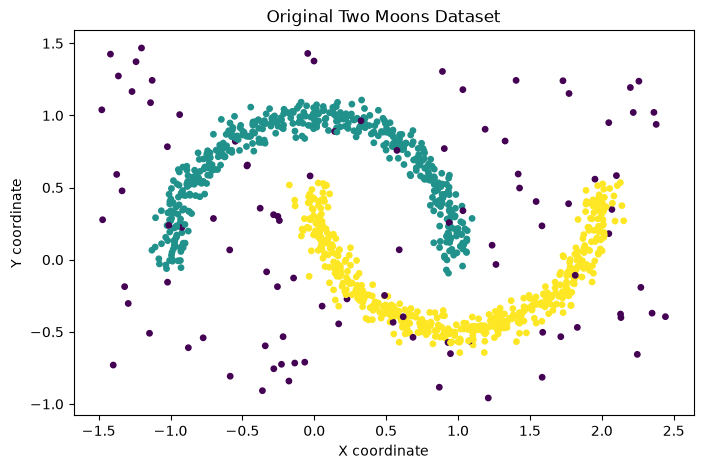

In [3]:
print("Dataset information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("\nOriginal label distribution:")
print(df["shape"].value_counts().sort_index())

plt.figure(figsize=(8, 5))
plt.scatter(df["x"], df["y"], c=df["shape"], cmap="viridis", s=15)
plt.title("Original Two Moons Dataset")
plt.xlabel("X coordinate")
plt.ylabel("Y coordinate")
plt.show()

In [4]:
X = df[["x", "y"]]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Features standardized successfully!")
print("Feature matrix shape:", X_scaled.shape)

Features standardized successfully!
Feature matrix shape: (1100, 2)


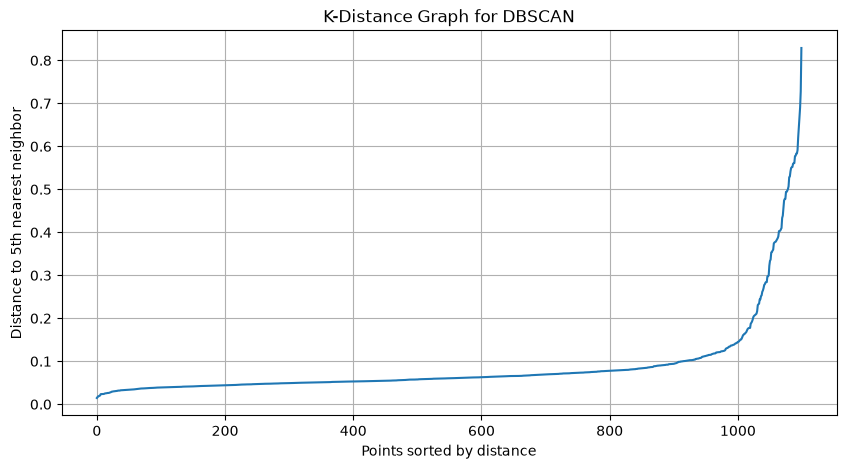

In [5]:
min_pts = 5

neighbors = NearestNeighbors(n_neighbors=min_pts)
neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(10, 5))
plt.plot(k_distances)
plt.title("K-Distance Graph for DBSCAN")
plt.xlabel("Points sorted by distance")
plt.ylabel("Distance to 5th nearest neighbor")
plt.grid(True)
plt.show()

In [6]:
eps_value = 0.22

dbscan = DBSCAN(eps=eps_value, min_samples=min_pts)
labels = dbscan.fit_predict(X_scaled)

df["DBSCAN_Cluster"] = labels

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = int(np.sum(labels == -1))
noise_percentage = (n_noise / len(labels)) * 100

print("--- DBSCAN Clustering Performance ---")
print(f"Optimal Epsilon (ε) : {eps_value}")
print(f"MinPts              : {min_pts}")
print(f"Number of Clusters  : {n_clusters}")
print(f"Number of Noise Points: {n_noise} ({noise_percentage:.2f}%)")

--- DBSCAN Clustering Performance ---
Optimal Epsilon (ε) : 0.22
MinPts              : 5
Number of Clusters  : 2
Number of Noise Points: 63 (5.73%)


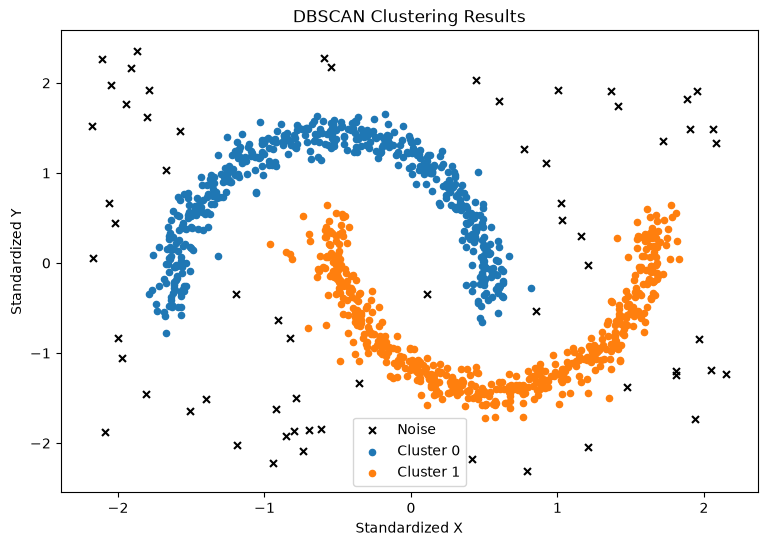

In [7]:
plt.figure(figsize=(9, 6))

unique_labels = sorted(set(labels))

for cluster in unique_labels:
    mask = labels == cluster

    if cluster == -1:
        plt.scatter(
            X_scaled[mask, 0],
            X_scaled[mask, 1],
            c="black",
            marker="x",
            s=25,
            label="Noise"
        )
    else:
        plt.scatter(
            X_scaled[mask, 0],
            X_scaled[mask, 1],
            s=20,
            label=f"Cluster {cluster}"
        )

plt.title("DBSCAN Clustering Results")
plt.xlabel("Standardized X")
plt.ylabel("Standardized Y")
plt.legend()
plt.show()

In [8]:
non_noise = labels != -1
valid_labels = labels[non_noise]

if len(np.unique(valid_labels)) >= 2:
    score = silhouette_score(
        X_scaled[non_noise],
        valid_labels
    )
    print(f"Silhouette Score (excluding noise): {score:.4f}")
else:
    print("Silhouette score cannot be calculated: fewer than 2 non-noise clusters.")

Silhouette Score (excluding noise): 0.3824


In [9]:
print("========== FINAL RESULTS ==========")
print("Total samples:", len(df))
print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)
print(f"Noise percentage: {noise_percentage:.2f}%")

print("\nCluster distribution:")
print(df["DBSCAN_Cluster"].value_counts().sort_index())

display(df.head(10))

========== FINAL RESULTS ==========
Total samples: 1100
Number of clusters: 2
Number of noise points: 63
Noise percentage: 5.73%

Cluster distribution:
DBSCAN_Cluster
-1     63
 0    514
 1    523
Name: count, dtype: int64


,x,y,shape,DBSCAN_Cluster
0,-0.91523,0.47909,0,0
1,0.41194,-0.31666,1,1
2,0.51217,0.88467,0,0
3,1.43327,-0.36771,1,1
4,-0.96685,0.22511,0,0
5,0.97663,0.29596,0,0
6,0.21863,-0.00270,1,1
7,-0.05332,1.06650,0,0
8,0.05273,0.07442,1,1
9,0.62052,-0.42944,1,1


In [10]:
print("Name :Manthan Mishra")
print ("PRN No.:72421206B")

Name :Manthan Mishra
PRN No.:72421206B
